# B6 — Gán nhãn giả (Pseudo-Labeling), Ensemble Voting & Gộp Dữ liệu Vòng 2

**Mục tiêu của Bước 6 (B6):**
1. Dùng 7 mô hình Run 2 (`B5` — đã mạnh hơn và hội tụ đủ 7/7 kể cả `ViDeBERTa-base`) suy luận xác suất 4 lớp trên phần dữ liệu còn dư sau Vòng 1 (`pseudo_round1/remain_data_r1.csv`, `~31.109` câu).
2. Chạy **Ensemble Consensus Voting Vòng 2** với ngưỡng hạ nhẹ (`confidence >= 0.91`, `margin >= 0.45`, `min_vote_ratio = 0.60`, kèm **Quality Gate** `min_model_val_f1 = 0.50`) → xuất `ensemble_pseudo_r2.csv` và `remain_data_r2.csv`.
3. Gộp có chọn lọc vào `combined_round1.csv` (ưu tiên kéo mạnh lớp 0 `Irrelevant` lên cân bằng cùng 3 lớp kia quanh mục tiêu `10.500` mẫu/lớp!) → **`combined_round2.csv` (~40k–42k mẫu cân bằng đều 4 lớp)**.
4. **Biểu đồ xuất tại `workspace_outputs/figures/B6_pseudo_round2/` (300 DPI `.png` + `.pdf`):**
   - `B6_01_bieu_do_pheu_unlabeled`: Biểu đồ phễu (Data Funnel) theo dõi trọn vẹn luồng `54.487` câu không nhãn qua 2 vòng.
   - `B6_02_phan_bo_du_lieu_3_tang`: Biểu đồ cột chồng 3 tầng (`Original + Pseudo Vòng 1 + Pseudo Vòng 2`) cho 4 lớp ESG.
   - `B6_03_phan_bo_confidence_vong2` & `B6_04_ma_tran_dong_thuan_kappa_vong2`: Kiểm chứng độ tin cậy & Cohen's Kappa khi đủ 7/7 mô hình hội tụ.

In [1]:
# Bước 6.1: Khởi tạo cấu hình & công tắc linh hoạt cho Vòng 2
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    PipelineConfig,
    ensure_directories,
    set_global_seed,
    get_figure_dir,
    PROCESSED_DATA_DIR,
    CHECKPOINTS_DIR,
    PSEUDO_ROUND1_DIR,
    PSEUDO_ROUND2_DIR,
    METRICS_DIR,
    LABEL_NAMES,
)
from src.pseudo_labeler import UnsupervisedPseudoLabeler
from src.ensemble import EnsembleVoter
from src.combiner import SelectiveDataCombiner
from src.viz_utils import (
    plot_unlabeled_data_funnel,
    plot_three_tier_class_distribution,
    plot_pseudo_confidence_distribution,
    plot_pairwise_agreement_heatmap,
)

ensure_directories()

# ==================== CÔNG TẮC LINH HOẠT CHO BƯỚC B6 ====================
cfg = PipelineConfig(
    hardware_mode="balanced",
    model_preset="full_7",
    skip_if_done=True,
    round2_confidence_threshold=0.91,
    round2_min_margin=0.45,
    round2_min_vote_ratio=0.60,           # >= 5/7 mô hình đồng thuận
    round2_target_per_class=10_500,
    use_weighted_voting=True,
)
# Nếu muốn tự chỉ định số lượng thêm từng lớp ở Vòng 2, gán dict vd: {0: 3500, 1: 1000, 2: 1000, 3: 1000}
CUSTOM_ADD_COUNTS_R2 = None
# ========================================================================

set_global_seed(cfg.seed)
FIG_DIR = get_figure_dir("B6")

print(cfg.summary())
print(f"\nNơi lưu kết quả Pseudo Vòng 2: {PSEUDO_ROUND2_DIR}")
print(f"Nơi lưu biểu đồ Bước B6      : {FIG_DIR}")

=== CẤU HÌNH HỆ THỐNG VI-ESG-BERT ===
- Chế độ phần cứng : balanced (train_bs=16 x accum=2, bf16=True, grad_ckpt=False, nghỉ=15s)
- Gói mô hình      : full_7 (7 mô hình: phobert-base, distilbert-base-multilingual-cased, bert-base-multilingual-cased, roberta-base, electra-base-vn, visobert, videberta-base)
- Ablation Baseline: bật=True | gói=fast_3 (electra-base-vn, phobert-base, visobert)
- Công tắc an toàn : skip_if_done=True | seed=42
- Siêu tham số     : max_length=256 | lr=2e-05 | warmup=0.1 | metric=f1_macro
- Pseudo & Cân bằng: R1(conf>=0.94, margin>=0.5, target=9,500/lớp) | R2(conf>=0.91, target=10,500/lớp)
- Thư mục biểu đồ  : D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures (DPI=300, PDF=True)

Nơi lưu kết quả Pseudo Vòng 2: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\pseudo_round2
Nơi lưu biểu đồ Bước B6      : D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_ou

In [2]:
# Bước 6.2: Nạp remain_data_r1.csv, combined_round1.csv và trọng số Val Macro-F1 từ Run 2 (B5)
remain_r1_path = PSEUDO_ROUND1_DIR / "remain_data_r1.csv"
combined_r1_path = PSEUDO_ROUND1_DIR / "combined_round1.csv"
assert remain_r1_path.exists() and combined_r1_path.exists(), "Cần chạy xong B4 & B5 trước khi chạy B6!"

remain_r1_df = pd.read_csv(remain_r1_path)
combined_r1_df = pd.read_csv(combined_r1_path)

print(f"- remain_data_r1.csv  : {len(remain_r1_df):,} mẫu chưa gán nhãn từ Vòng 1")
print(f"- combined_round1.csv : {len(combined_r1_df):,} mẫu hiện có trước Vòng 2")

ready_models = []
model_weights = {}
for spec in cfg.get_active_models():
    ckpt_dir = CHECKPOINTS_DIR / "run2" / spec.short_name
    summary_path = METRICS_DIR / f"run2_{spec.short_name}_train_summary.json"
    if (ckpt_dir / "model_metadata.json").exists():
        ready_models.append(spec)
        if summary_path.exists():
            with open(summary_path, "r", encoding="utf-8") as f:
                s = json.load(f)
            model_weights[spec.display_name] = float(s.get("best_val_metrics", {}).get("eval_f1_macro", 1.0))
        else:
            model_weights[spec.display_name] = 1.0
    else:
        print(f"[Cảnh báo] Chưa có checkpoint Run 2 cho {spec.display_name} -> bỏ qua.")

print(f"\nSố mô hình Run 2 sẵn sàng: {len(ready_models)} -> {[m.display_name for m in ready_models]}")
print(f"Trọng số bỏ phiếu (Val Macro-F1 R2): { {k: round(v, 4) for k, v in model_weights.items()} }")
assert len(ready_models) >= 2, "Cần ít nhất 2 mô hình Run 2 đã huấn luyện ở Bước B5!"

- remain_data_r1.csv  : 31,109 mẫu chưa gán nhãn từ Vòng 1
- combined_round1.csv : 34,404 mẫu hiện có trước Vòng 2

Số mô hình Run 2 sẵn sàng: 7 -> ['PhoBERT-base', 'DistilBERT-m', 'mBERT-cased', 'RoBERTa-base', 'Vi-ELECTRA', 'ViSoBERT', 'ViDeBERTa-base']
Trọng số bỏ phiếu (Val Macro-F1 R2): {'PhoBERT-base': 0.8978, 'DistilBERT-m': 0.8886, 'mBERT-cased': 0.9007, 'RoBERTa-base': 0.8488, 'Vi-ELECTRA': 0.9093, 'ViSoBERT': 0.8722, 'ViDeBERTa-base': 0.8403}


In [3]:
# Bước 6.3: Suy luận xác suất 4 lớp của các mô hình Run 2 trên remain_data_r1.csv
labeler = UnsupervisedPseudoLabeler(cfg)
per_model_files_r2 = {}
per_model_confs_r2 = {}

for spec in ready_models:
    ckpt_dir = CHECKPOINTS_DIR / "run2" / spec.short_name
    out_parquet = PSEUDO_ROUND2_DIR / "per_model" / f"{spec.short_name}_r2.parquet"

    pred_df = labeler.predict_unlabeled(
        model_spec=spec,
        checkpoint_dir=ckpt_dir,
        unlabeled_df=remain_r1_df,
        output_path=out_parquet,
        round_tag="r2",
    )
    per_model_files_r2[spec.display_name] = out_parquet
    per_model_confs_r2[spec.display_name] = pred_df["confidence"].to_numpy(dtype=np.float32)

print("\n[HOÀN TẤT] Đã sinh đủ tệp xác suất .parquet Vòng 2!")


[Pseudo-Labeling r2] Mô hình: PhoBERT-base | Số câu: 31,109 | pyvi=True
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run2\phobert-base


W1122 22:59:26.611000 11696 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Pseudo [r2] PhoBERT-base: 100%|██████████| 487/487 [00:12<00:00, 40.47batch/s]


  => Xong PhoBERT-base: 20,787/31,109 mẫu đạt conf >= 0.91 (66.82%) | Tốc độ=2546.5 mẫu/s (12.2s)

[Pseudo-Labeling r2] Mô hình: DistilBERT-m | Số câu: 31,109 | pyvi=False
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run2\distilbert-base-multilingual-cased


Pseudo [r2] DistilBERT-m: 100%|██████████| 487/487 [00:09<00:00, 53.89batch/s]


  => Xong DistilBERT-m: 24,688/31,109 mẫu đạt conf >= 0.91 (79.36%) | Tốc độ=3388.7 mẫu/s (9.2s)

[Pseudo-Labeling r2] Mô hình: mBERT-cased | Số câu: 31,109 | pyvi=False
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run2\bert-base-multilingual-cased


Pseudo [r2] mBERT-cased: 100%|██████████| 487/487 [00:14<00:00, 33.72batch/s]


... (5 outputs left out)

Pseudo [r2] ViSoBERT: 100%|██████████| 487/487 [00:17<00:00, 28.33batch/s]


  => Xong ViSoBERT: 28,025/31,109 mẫu đạt conf >= 0.91 (90.09%) | Tốc độ=1797.0 mẫu/s (17.3s)

[Pseudo-Labeling r2] Mô hình: ViDeBERTa-base | Số câu: 31,109 | pyvi=False
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\checkpoints\run2\videberta-base


Pseudo [r2] ViDeBERTa-base: 100%|██████████| 487/487 [00:25<00:00, 19.38batch/s]


  => Xong ViDeBERTa-base: 16,957/31,109 mẫu đạt conf >= 0.91 (54.51%) | Tốc độ=1227.7 mẫu/s (25.3s)

[HOÀN TẤT] Đã sinh đủ tệp xác suất .parquet Vòng 2!


In [4]:
# Bước 6.4: Chạy Ensemble Consensus Voting Vòng 2 (kèm Quality Gate min_model_val_f1=0.50)
voter_r2 = EnsembleVoter(
    confidence_threshold=cfg.round2_confidence_threshold,
    min_vote_ratio=cfg.round2_min_vote_ratio,
    min_margin=cfg.round2_min_margin,
    model_weights=model_weights,
    use_weighted_voting=cfg.use_weighted_voting,
    min_model_val_f1=0.50,
)

ensemble_pseudo_r2, remain_data_r2, ensemble_report_r2 = voter_r2.vote_pseudo_labels(
    per_model_files=per_model_files_r2,
    unlabeled_df=remain_r1_df,
    output_dir=PSEUDO_ROUND2_DIR,
    round_tag="r2",
    text_col=cfg.text_column,
)

display(ensemble_pseudo_r2[["text_id", "vi_text", "label_name", "confidence", "margin", "vote_count"]].head(5))


[ENSEMBLE VOTING R2] Hoàn tất bỏ phiếu 7 mô hình!
  - Điều kiện lọc : vote >= 5/7 | conf >= 0.91 | margin >= 0.45 | Hard == Soft
  - Kết quả       : Giữ 9,525/31,109 mẫu (30.62%) | Còn dư 21,584 mẫu
  - Chất lượng    : Avg Conf=0.9738 | Avg Margin=0.9522 | Mean Kappa=0.5714
  - Phân bố nhãn  : {'Irrelevant': 1844, 'Environment': 2277, 'Social': 1813, 'Governance': 3591}


,text_id,vi_text,label_name,confidence,margin,vote_count
0,unl_012309,công việc thu gom khí trong môi trường của chú...,Environment,0.999587,0.999426,7
1,unl_022143,sự đốt cháy những nhiên liêu cực ít lưu huỳnh ...,Environment,0.999576,0.999398,7
2,unl_038917,sản xuất khí đốt trong khí tự nhiên từ việc rò...,Environment,0.999564,0.999387,7
3,unl_024227,so với các quy trình sản xuất nguyên liệu thô ...,Environment,0.999541,0.999334,7
4,unl_050653,công ty chúng tôi cũng tìm kiếm quyền khai thá...,Environment,0.999540,0.999307,7


In [5]:
# Bước 6.5: Gộp chọn lọc Vòng 2 vào combined_round1.csv -> combined_round2.csv (tập train cuối cùng)
combiner = SelectiveDataCombiner(text_col=cfg.text_column, label_col=cfg.label_column, seed=cfg.seed)

suggested_r2 = combiner.suggest_balanced_counts(
    original_df=combined_r1_df,
    pseudo_df=ensemble_pseudo_r2,
    target_per_class=cfg.round2_target_per_class,
)

add_counts_r2 = CUSTOM_ADD_COUNTS_R2 if CUSTOM_ADD_COUNTS_R2 is not None else suggested_r2
print(f"\nSố lượng áp dụng gộp Vòng 2: {add_counts_r2}")

combined_round2_df, remaining_pseudo_r2_df, dist_info_r2 = combiner.combine(
    original_df=combined_r1_df,
    pseudo_df=ensemble_pseudo_r2,
    add_counts=add_counts_r2,
    output_dir=PSEUDO_ROUND2_DIR,
    round_name="round2",
)

=== GỢI Ý SỐ LƯỢNG GỘP CÂN BẰNG LỚP ===
Lớp                |  Hiện có | Pseudo có sẵn | Đề xuất thêm | Tổng sau gộp
--------------------------------------------------------------------------
0 - Irrelevant     |    5,904 |         1,844 |        1,844 |        7,748
1 - Environment    |    9,500 |         2,277 |        1,000 |       10,500
2 - Social         |    9,500 |         1,813 |        1,000 |       10,500
3 - Governance     |    9,500 |         3,591 |        1,000 |       10,500

Số lượng áp dụng gộp Vòng 2: {0: 1844, 1: 1000, 2: 1000, 3: 1000}

=== KẾT QUẢ GỘP DỮ LIỆU (ROUND2) ===
  Lớp 0 (Irrelevant ):  5,904 (trước) + 1,844 (pseudo) =  7,748 (sau) | Dư pseudo:     0
  Lớp 1 (Environment):  9,500 (trước) + 1,000 (pseudo) = 10,500 (sau) | Dư pseudo: 1,277
  Lớp 2 (Social     ):  9,500 (trước) + 1,000 (pseudo) = 10,500 (sau) | Dư pseudo:   813
  Lớp 3 (Governance ):  9,500 (trước) + 1,000 (pseudo) = 10,500 (sau) | Dư pseudo: 2,591
  => Tổng mẫu: 34,404 -> 39,248 (+4,844 pseu

[Đã lưu biểu đồ] B6_01_bieu_do_pheu_unlabeled.png, B6_01_bieu_do_pheu_unlabeled.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B6_pseudo_round2


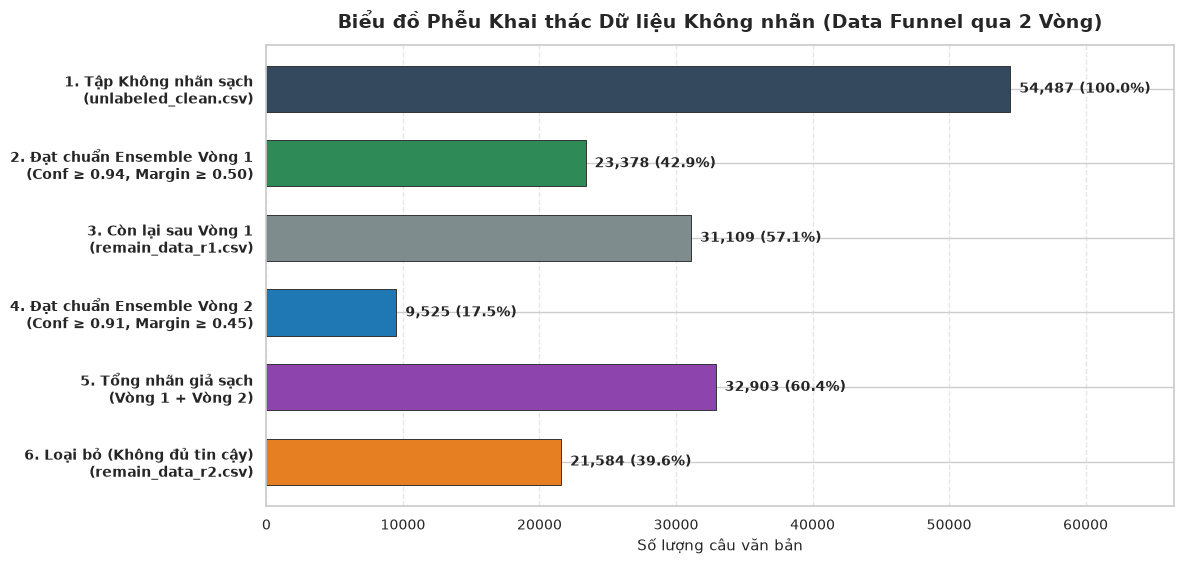

[Đã lưu biểu đồ] B6_02_phan_bo_du_lieu_3_tang.png, B6_02_phan_bo_du_lieu_3_tang.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B6_pseudo_round2


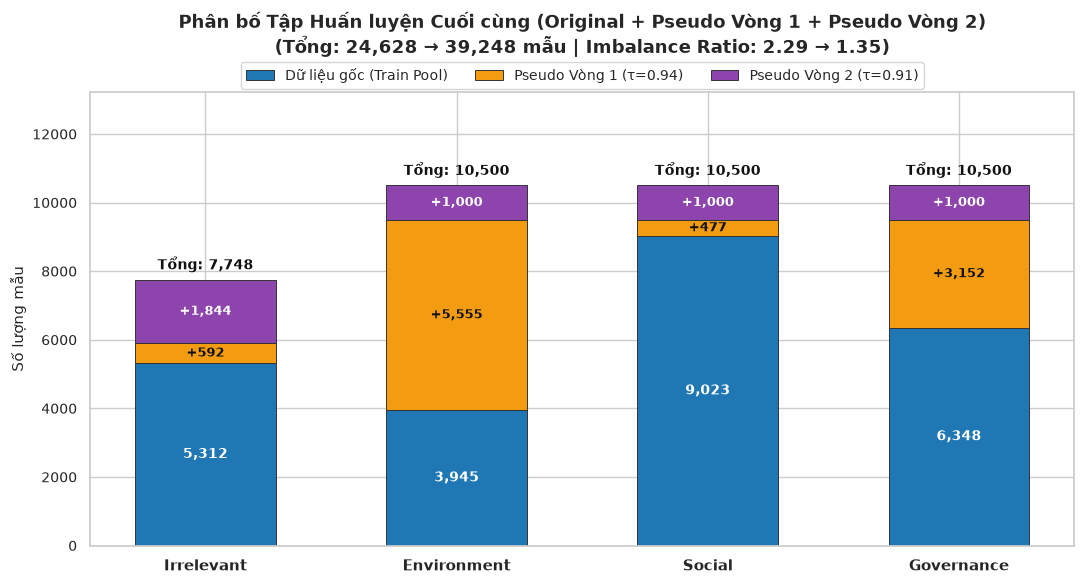

In [6]:
# Bước 6.6 — Biểu đồ B6.1 (Data Funnel qua 2 vòng) & B6.2 (Stacked Bar 3 tầng: Original + Pseudo 1 + Pseudo 2)
with open(PSEUDO_ROUND1_DIR / "ensemble_report_r1.json", "r", encoding="utf-8") as f:
    ensemble_report_r1 = json.load(f)
with open(PSEUDO_ROUND1_DIR / "distribution_round1.json", "r", encoding="utf-8") as f:
    dist_info_r1 = json.load(f)

fig_funnel = plot_unlabeled_data_funnel(
    total_unlabeled=ensemble_report_r1["input_unlabeled_count"],
    r1_selected=ensemble_report_r1["selected_pseudo_count"],
    r2_selected=ensemble_report_r2["selected_pseudo_count"],
    r2_remain=ensemble_report_r2["remain_count"],
    save_dir=FIG_DIR,
    filename_stem="B6_01_bieu_do_pheu_unlabeled",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

fig_3tier = plot_three_tier_class_distribution(
    dist_r1=dist_info_r1,
    dist_r2=dist_info_r2,
    save_dir=FIG_DIR,
    filename_stem="B6_02_phan_bo_du_lieu_3_tang",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

[Đã lưu biểu đồ] B6_03_phan_bo_confidence_vong2.png, B6_03_phan_bo_confidence_vong2.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B6_pseudo_round2


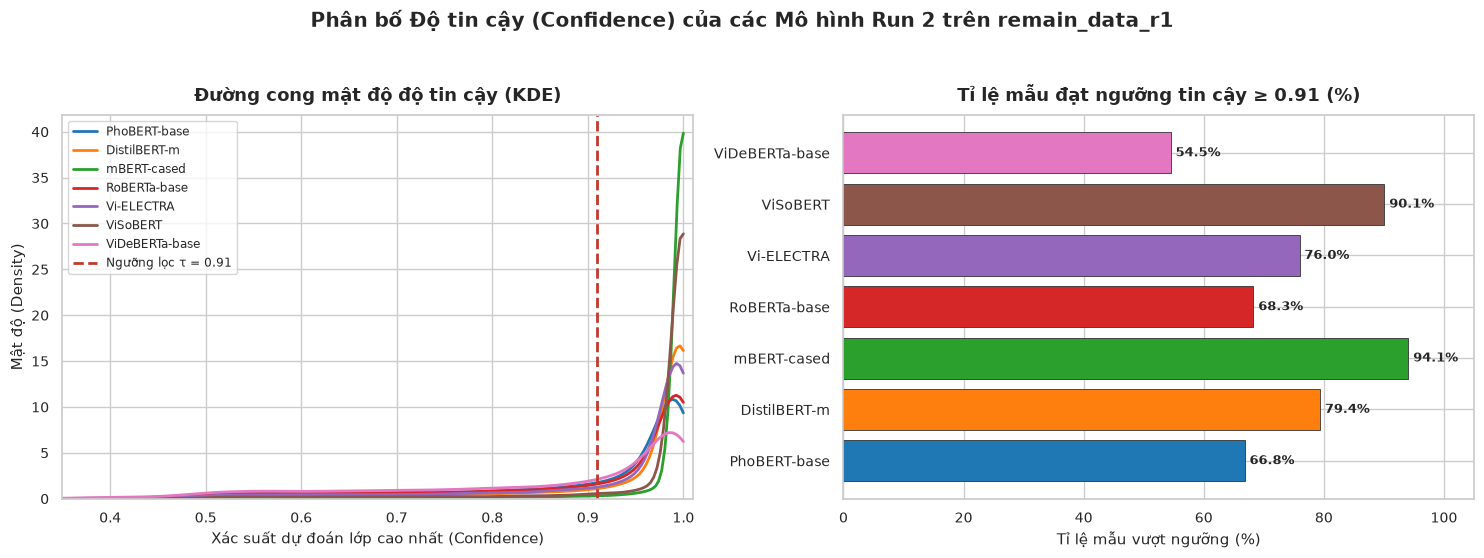

[Đã lưu biểu đồ] B6_04_ma_tran_dong_thuan_kappa_vong2.png, B6_04_ma_tran_dong_thuan_kappa_vong2.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B6_pseudo_round2


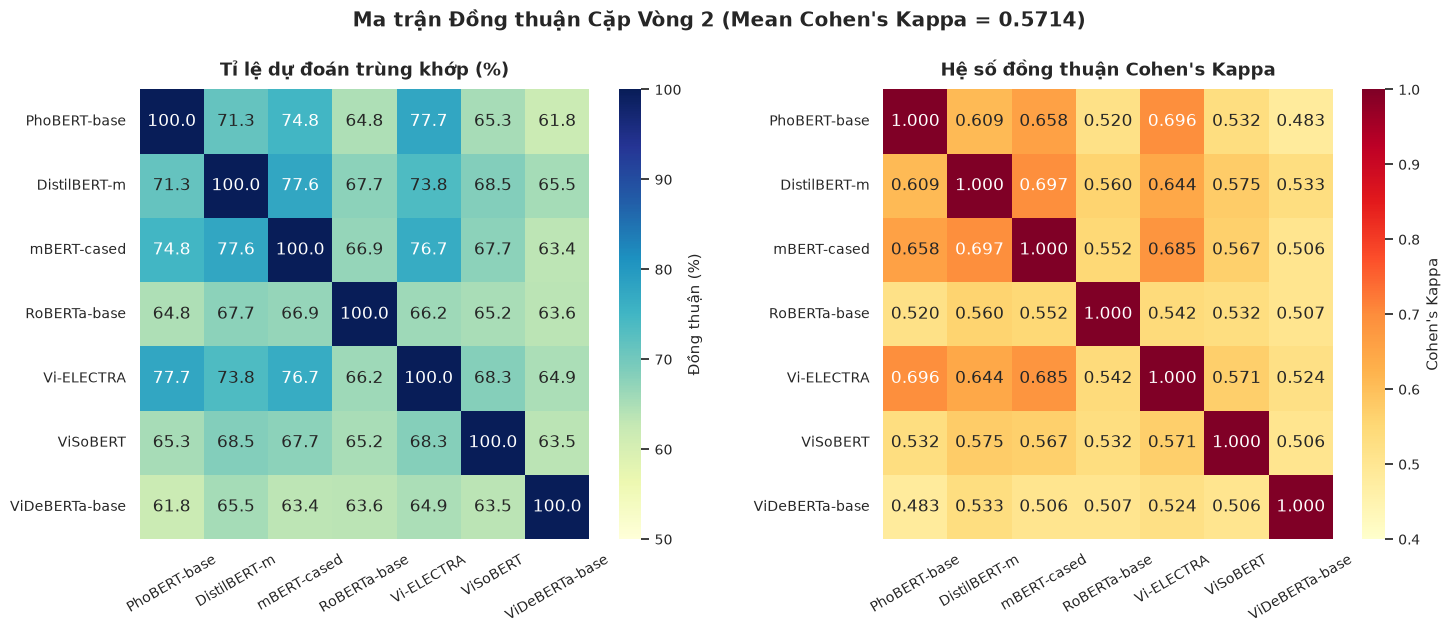


=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B6_pseudo_round2 ===
  - B6_01_bieu_do_pheu_unlabeled.pdf
  - B6_01_bieu_do_pheu_unlabeled.png
  - B6_02_phan_bo_du_lieu_3_tang.pdf
  - B6_02_phan_bo_du_lieu_3_tang.png
  - B6_03_phan_bo_confidence_vong2.pdf
  - B6_03_phan_bo_confidence_vong2.png
  - B6_04_ma_tran_dong_thuan_kappa_vong2.pdf
  - B6_04_ma_tran_dong_thuan_kappa_vong2.png


In [7]:
# Bước 6.7 — Biểu đồ B6.3 (Confidence KDE Vòng 2) & B6.4 (Ma trận Đồng thuận & Cohen's Kappa Vòng 2)
fig_conf_r2 = plot_pseudo_confidence_distribution(
    per_model_confs=per_model_confs_r2,
    threshold=cfg.round2_confidence_threshold,
    title="Phân bố Độ tin cậy (Confidence) của các Mô hình Run 2 trên remain_data_r1",
    save_dir=FIG_DIR,
    filename_stem="B6_03_phan_bo_confidence_vong2",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

agree_r2_df = pd.DataFrame(ensemble_report_r2["pairwise_agreement_pct"])
kappa_r2_df = pd.DataFrame(ensemble_report_r2["pairwise_cohen_kappa"])
fig_kappa_r2 = plot_pairwise_agreement_heatmap(
    agreement_df=agree_r2_df,
    kappa_df=kappa_r2_df,
    title=f"Ma trận Đồng thuận Cặp Vòng 2 (Mean Cohen's Kappa = {ensemble_report_r2['mean_pairwise_kappa']:.4f})",
    save_dir=FIG_DIR,
    filename_stem="B6_04_ma_tran_dong_thuan_kappa_vong2",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

print("\n=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B6_pseudo_round2 ===")
for p in sorted(FIG_DIR.glob("*")):
    print(f"  - {p.name}")